In [66]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.metrics import f1_score
from src.decoupage import decouper, evaluer
from src.voisins import entrainer, voisins

X_ent, X_val, X_test, y_ent, y_val, y_test = decouper()

print("Entraînement :", X_ent.shape, " Validation :", X_val.shape, " Test :", X_test.shape)
print("Colonnes :", list(X_ent.columns))
print("Type de y :", y_ent.dtype, "| valeurs :", y_ent.unique()[:5])

Entraînement : (16466, 10)  Validation : (3529, 10)  Test : (3529, 10)
Colonnes : ['country', 'location_type', 'cellphone_access', 'household_size', 'age_of_respondent', 'gender_of_respondent', 'relationship_with_head', 'marital_status', 'education_level', 'job_type']
Type de y : int64 | valeurs : [0 1]


In [67]:
import importlib
import src.voisins
importlib.reload(src.voisins)          # ← indispensable après chaque modif du .py
from src.voisins import entrainer, voisins
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

# 1) entraîner un objet d'exploration en mémoire
objet_explo = entrainer(X_ent, y_ent, k=100, seuil=0.5)
print("OK, X_enc shape =", objet_explo["X_enc"].shape)

# 2) tester voisins() avec cet objet (sans passer par le disque)
res = voisins(X_val.iloc[[0]], k=25, objet=objet_explo)
print(res)   # → {"k": 25, "taux": ..., "taux_meme_pays": ...}

OK, X_enc shape = (16466, 32)
{'k': 25, 'taux': 0.12, 'taux_meme_pays': 0.16}


In [68]:
print("dtype :", y_ent.dtype)
print("valeurs uniques :", y_ent.unique())
print("NaN :", y_ent.isna().sum())
print("---")
print("dtype :", y_val.dtype)
print("valeurs uniques :", y_val.unique())
print("NaN :", y_val.isna().sum())

dtype : int64
valeurs uniques : [0 1]
NaN : 0
---
dtype : int64
valeurs uniques : [0 1]
NaN : 0


In [69]:
# Pas de conversion : y est déjà en 0/1
y_ent_b  = y_ent
y_val_b  = y_val
y_test_b = y_test

In [70]:
print(type(objet_explo))   # doit afficher <class 'dict'>

<class 'dict'>


## **Choix de la distance**
Le KNN compare des profils, il faut donc que toutes les variables contribuent équitablement à la distance. Deux problèmes :

Les catégorielles ne sont pas numériques → on les passe en one-hot.

L'âge et la taille du ménage varient sur des échelles très différentes (0–1 pour un one-hot, dizaines/centaines pour l'âge). Sans standardisation, l'âge écraserait toutes les autres variables dans la distance euclidienne.

→ On applique donc one-hot + standardisation des deux numériques (via un ColumnTransformer dans src/voisins.py). La distance de Gower est une alternative valable, mais plus coûteuse à coder et équivalente en esprit ici.



In [71]:
def predire_avec(profil_df, k, seuil, variante="global", objet=None):
    preds = []
    for _, ligne in profil_df.iterrows():
        res = voisins(ligne.to_frame().T, k=k, objet=objet)
        taux = res["taux"] if variante == "global" else res["taux_meme_pays"]
        preds.append(1 if taux >= seuil else 0)
    return np.array(preds)


def f1_macro_avec(profil_df, y_vrai, k, seuil, variante="global", objet=None):
    y_pred = predire_avec(profil_df, k, seuil, variante, objet=objet)
    return f1_score(y_vrai, y_pred, average="macro")

In [72]:
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

# ------------------------------------------------------------------
# 1) Calcul batch des taux KNN (un seul kneighbors par k et par variante)
# ------------------------------------------------------------------
def taux_val_batch(objet, X_val, k, variante="global"):
    """Taux KNN pour toutes les lignes de X_val, en un seul kneighbors."""
    Xv = X_val[objet["colonnes"]]
    Xv_enc = objet["encodeur"].transform(Xv)
    if hasattr(Xv_enc, "toarray"):
        Xv_enc = Xv_enc.toarray()

    if variante == "global":
        _, idx = objet["nn_global"].kneighbors(Xv_enc, n_neighbors=k)
        return np.array([objet["y"][row].mean() for row in idx])

    # variante "meme_pays" : un kneighbors par pays (13 pays, pas 2500 lignes)
    taux = np.zeros(len(Xv))
    pays_col = objet["colonne_pays"]
    for pays, idx_pays in objet["index_pays"].items():
        masque = (Xv[pays_col] == pays).to_numpy()
        if not masque.any():
            continue
        k_pays = min(k, len(idx_pays["y"]))
        _, ind = idx_pays["nn"].kneighbors(Xv_enc[masque], n_neighbors=k_pays)
        taux[masque] = [idx_pays["y"][row].mean() for row in ind]
    return taux

# ------------------------------------------------------------------
# 2) Grille k × seuil (tous pays) — rapide
# ------------------------------------------------------------------
ks = [5, 10, 25, 50, 100]
seuils = np.linspace(0.05, 0.95, 19)

resultats = []
for k in ks:
    taux_val = taux_val_batch(objet_explo, X_val, k, variante="global")
    for s in seuils:
        y_pred = (taux_val >= s).astype(int)
        f1 = f1_score(y_val, y_pred, average="macro")
        resultats.append({"k": k, "seuil": s, "f1": f1})

df_res = pd.DataFrame(resultats)

# meilleur seuil par k
best_par_k = (
    df_res.loc[df_res.groupby("k")["f1"].idxmax()]
    .sort_values("k")
    .reset_index(drop=True)
)
print(best_par_k)

     k  seuil        f1
0    5   0.25  0.692121
1   10   0.35  0.689148
2   25   0.35  0.709642
3   50   0.35  0.718705
4  100   0.30  0.719168


In [73]:
best_par_k = (
    df_res.loc[df_res.groupby("k")["f1"].idxmax()]
    .sort_values("k")
    .reset_index(drop=True)
)
best_par_k

,k,seuil,f1
0,5,0.25,0.692121
1,10,0.35,0.689148
2,25,0.35,0.709642
3,50,0.35,0.718705
4,100,0.30,0.719168


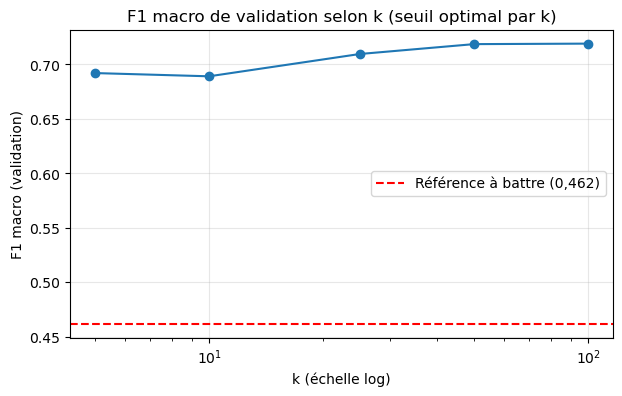

In [74]:
plt.figure(figsize=(7, 4))
plt.plot(best_par_k["k"], best_par_k["f1"], marker="o")
plt.axhline(0.462, color="red", linestyle="--", label="Référence à battre (0,462)")
plt.xscale("log")
plt.xlabel("k (échelle log)")
plt.ylabel("F1 macro (validation)")
plt.title("F1 macro de validation selon k (seuil optimal par k)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Un k trop petit (5) donne un taux instable (bruité), un k trop grand (100) lisse trop et ne décrit plus le profil. On retient le k au meilleur F1.

In [75]:
K_RETENU = 100
SEUIL_RETENU = 0.30

# contrôle
best_par_k.loc[best_par_k["k"] == K_RETENU]

,k,seuil,f1
4,100,0.3,0.719168


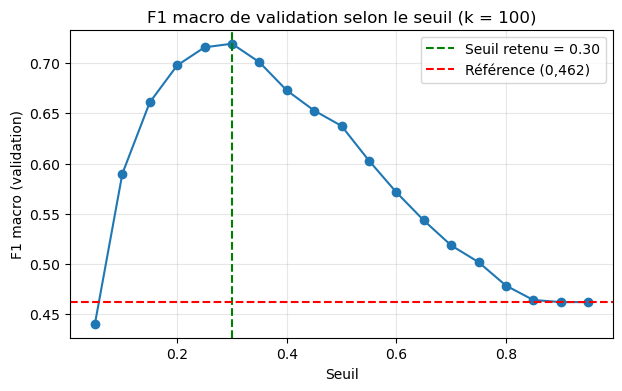

In [76]:
df_k = df_res[df_res["k"] == K_RETENU]

plt.figure(figsize=(7, 4))
plt.plot(df_k["seuil"], df_k["f1"], marker="o")
plt.axvline(SEUIL_RETENU, color="green", linestyle="--",
            label=f"Seuil retenu = {SEUIL_RETENU:.2f}")
plt.axhline(0.462, color="red", linestyle="--", label="Référence (0,462)")
plt.xlabel("Seuil")
plt.ylabel("F1 macro (validation)")
plt.title(f"F1 macro de validation selon le seuil (k = {K_RETENU})")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [77]:
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

resultats_comp = []
for k in ks:
    taux_glob = taux_val_batch(objet_explo, X_val, k, "global")
    taux_pays = taux_val_batch(objet_explo, X_val, k, "meme_pays")
    for s in seuils:
        f1_g = f1_score(y_val, (taux_glob >= s).astype(int), average="macro")
        f1_p = f1_score(y_val, (taux_pays >= s).astype(int), average="macro")
        resultats_comp.append({"k": k, "seuil": s,
                               "f1_global": f1_g, "f1_meme_pays": f1_p})

df_comp = pd.DataFrame(resultats_comp)

best_comp = df_comp.groupby("k").agg(
    f1_global=("f1_global", "max"),
    f1_meme_pays=("f1_meme_pays", "max"),
).reset_index()
print(best_comp)

     k  f1_global  f1_meme_pays
0    5   0.692121      0.693720
1   10   0.689148      0.710484
2   25   0.709642      0.720288
3   50   0.718705      0.714965
4  100   0.719168      0.716316


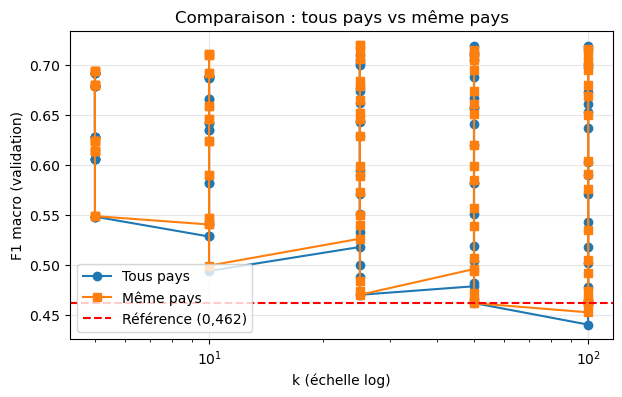

In [78]:
plt.figure(figsize=(7, 4))
plt.plot(df_comp["k"], df_comp["f1_global"], marker="o", label="Tous pays")
plt.plot(df_comp["k"], df_comp["f1_meme_pays"], marker="s", label="Même pays")
plt.axhline(0.462, color="red", linestyle="--", label="Référence (0,462)")
plt.xscale("log")
plt.xlabel("k (échelle log)")
plt.ylabel("F1 macro (validation)")
plt.title("Comparaison : tous pays vs même pays")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

« Même pays » est plus proche du profil culturel mais réduit le nombre de voisins disponibles (surtout pour les petits pays), donc le taux est plus bruité. Choisis la variante qui gagne sur la validation.

In [79]:
# On entraîne sur X_ent / y_ent avec les hyperparamètres retenus
objet = entrainer(X_ent, y_ent_b, k=K_RETENU, seuil=SEUIL_RETENU)

import os
os.makedirs("../models", exist_ok=True)
joblib.dump(objet, "../models/voisins.joblib")
print("Modèle sauvegardé dans models/voisins.joblib")

Modèle sauvegardé dans models/voisins.joblib


In [80]:
obj = joblib.load("../models/voisins.joblib")
profil = X_test.iloc[[0]]
res = voisins(profil)
print(res)
# doit afficher : {"k": ..., "taux": ..., "taux_meme_pays": ...}
assert set(res.keys()) == {"k", "taux", "taux_meme_pays"}

{'k': 100, 'taux': 0.02, 'taux_meme_pays': 0.01}


In [81]:
y_pred_test = predire_avec(X_test, K_RETENU, SEUIL_RETENU, variante="global")

# 1) avec evaluer() fourni par le socle
resultats_test = evaluer(X_test, y_test_b, y_pred_test)
print(resultats_test)

# 2) F1 macro global de contrôle
print("F1 macro test :", f1_score(y_test_b, y_pred_test, average="macro"))

                               effectif  f1_macro
groupe                                           
Global                             3529    0.7129
country = Kenya                     910    0.6935
country = Rwanda                   1311    0.6705
country = Tanzania                  993    0.7654
country = Uganda                    315    0.6817
gender_of_respondent = Female      2049    0.6940
gender_of_respondent = Male        1480    0.7177
F1 macro test : 0.7129027009437032
